<center><h1>Zhang_Zhengshu_HW1</h1></center>
<br>
<center><font size="4">Vertebral Column Data</font></center>
<br>

Name: Zhengshu Zhang

GitHub username: forestzs

USC ID: 4664738582

### (a) Download Data

Package imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch
from sklearn.neighbors import KNeighborsClassifier

%matplotlib inline
sns.set_theme(style="whitegrid")

Get the Vertebral Column Data Set

In [2]:
path = "data/vertebral_column_data/column_2C.dat"
cols = ["pelvic_incidence", "pelvic_tilt", "lumbar_lordosis_angle",
        "sacral_slope", "pelvic_radius", "grade_of_spondylolisthesis"]

df = pd.read_csv(path, sep=r"\s+", header=None, names=cols + ["class"])
df["class"] = df["class"].map({"NO": 0, "AB": 1}).astype(int)

print(df.shape)
print(df["class"].value_counts().sort_index())
df.head()

(310, 7)
class
0    100
1    210
Name: count, dtype: int64


,pelvic_incidence,pelvic_tilt,lumbar_lordosis_angle,sacral_slope,pelvic_radius,grade_of_spondylolisthesis,class
0,63.03,22.55,39.61,40.48,98.67,-0.25,1
1,39.06,10.06,25.02,29.00,114.41,4.56,1
2,68.83,22.22,50.09,46.61,105.99,-3.53,1
3,69.30,24.65,44.31,44.64,101.87,11.21,1
4,49.71,9.65,28.32,40.06,108.17,7.92,1


The data set is the Vertebral Column Data Set from the UCI Machine Learning Repository (https://archive.ics.uci.edu/ml/datasets/Vertebral+Column). The local copy of column_2C.dat is read from the data folder next to this notebook, and the string labels are converted to integers with NO = 0 and AB = 1.

### (b) Pre-Processing and Exploratory Data Analysis

#### i. Scatterplots

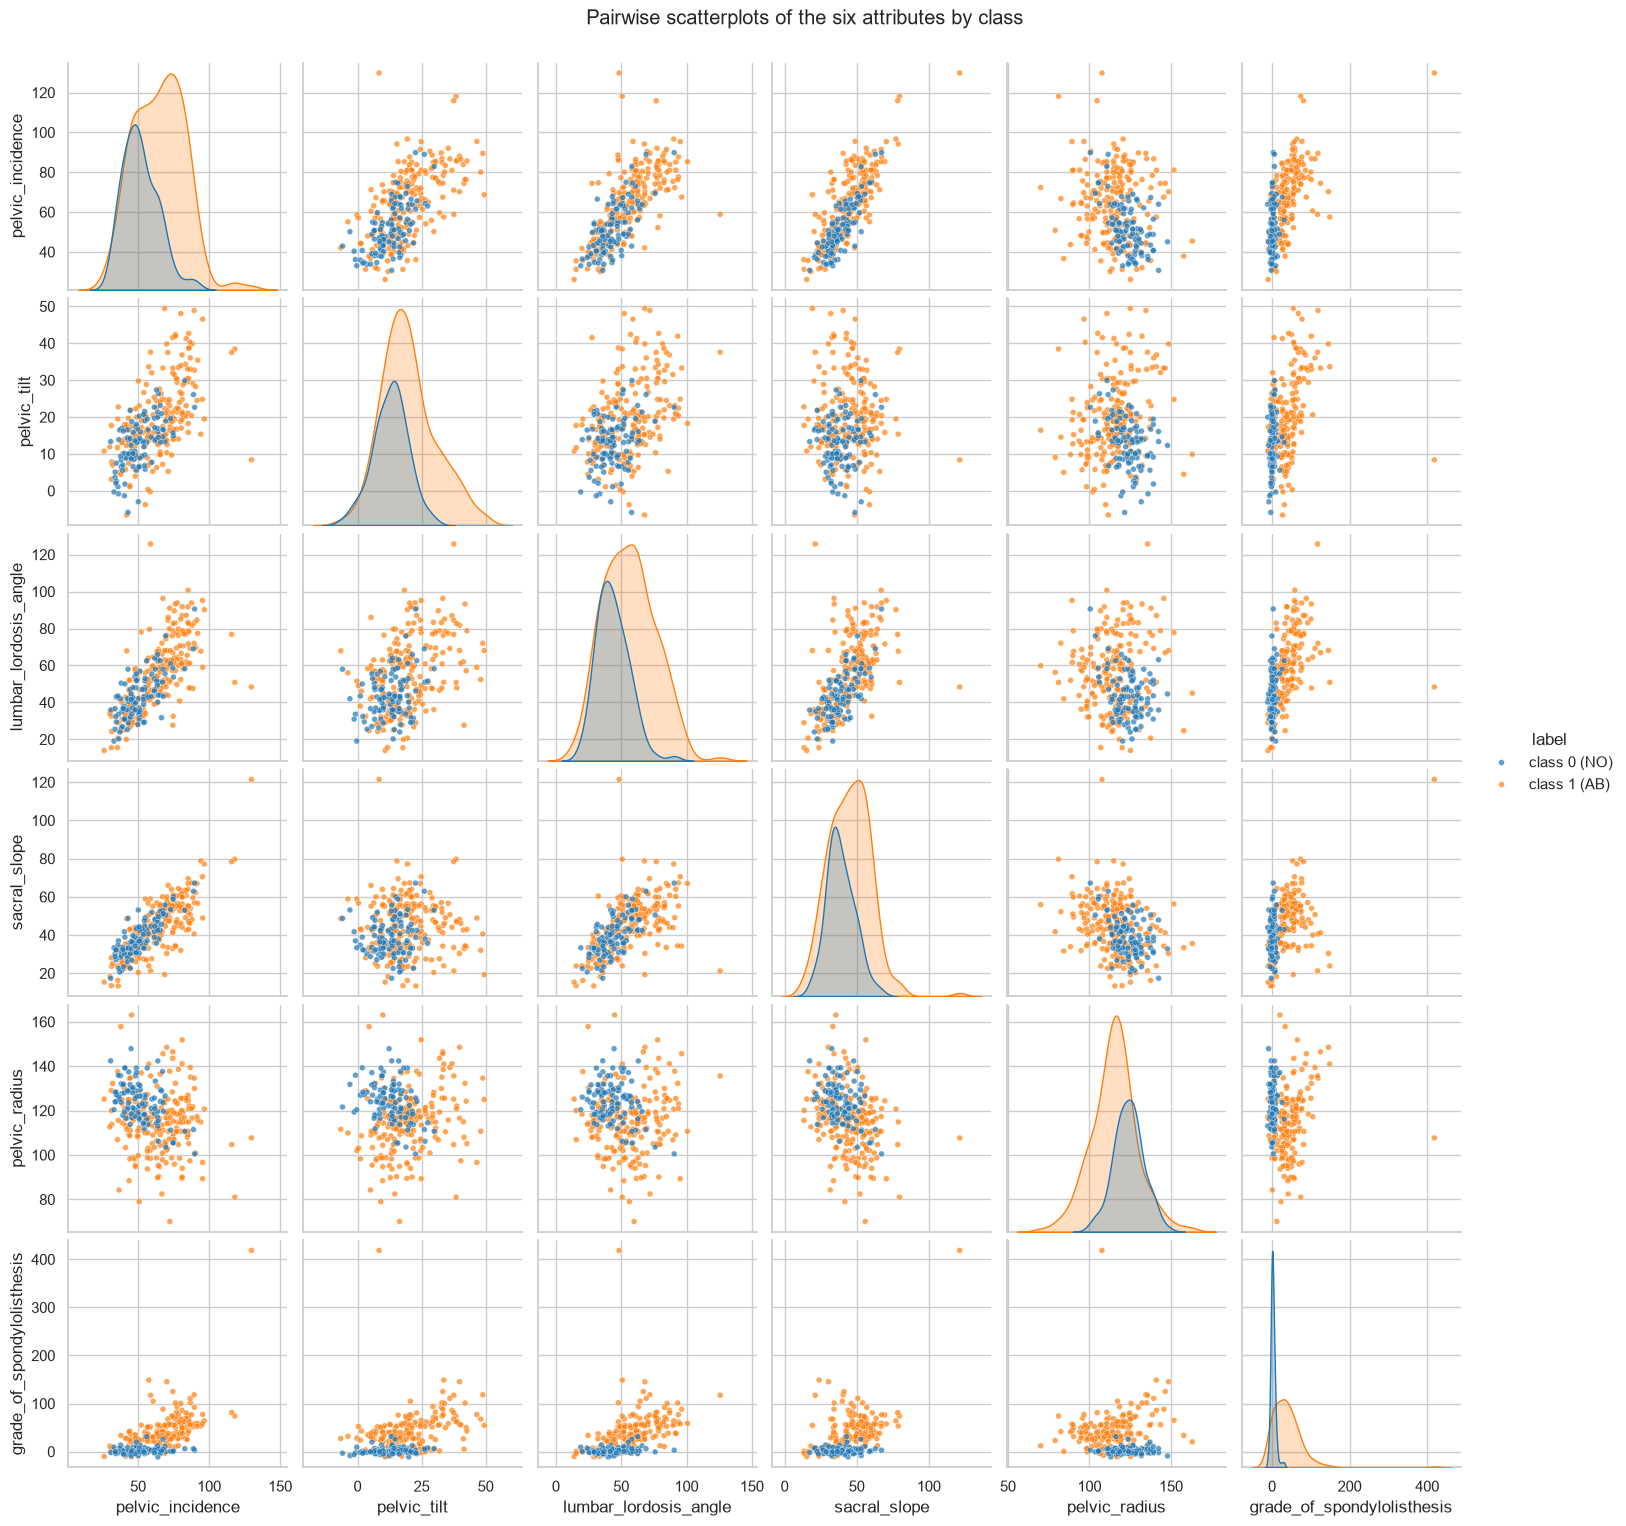

In [3]:
colors = {"class 0 (NO)": "tab:blue", "class 1 (AB)": "tab:orange"}
plot_df = df.assign(label=df["class"].map({0: "class 0 (NO)", 1: "class 1 (AB)"}))

g = sns.pairplot(plot_df, vars=cols, hue="label", hue_order=list(colors), palette=colors,
                 plot_kws={"s": 18, "alpha": 0.7}, diag_kind="kde")
g.fig.suptitle("Pairwise scatterplots of the six attributes by class", y=1.02)
plt.show()

Each off-diagonal panel is one of the fifteen attribute pairs, with the two classes in different colours and the diagonal showing the density of each attribute per class. Grade of spondylolisthesis separates the classes most clearly, while the other attributes overlap heavily between classes.

#### ii. Boxplots

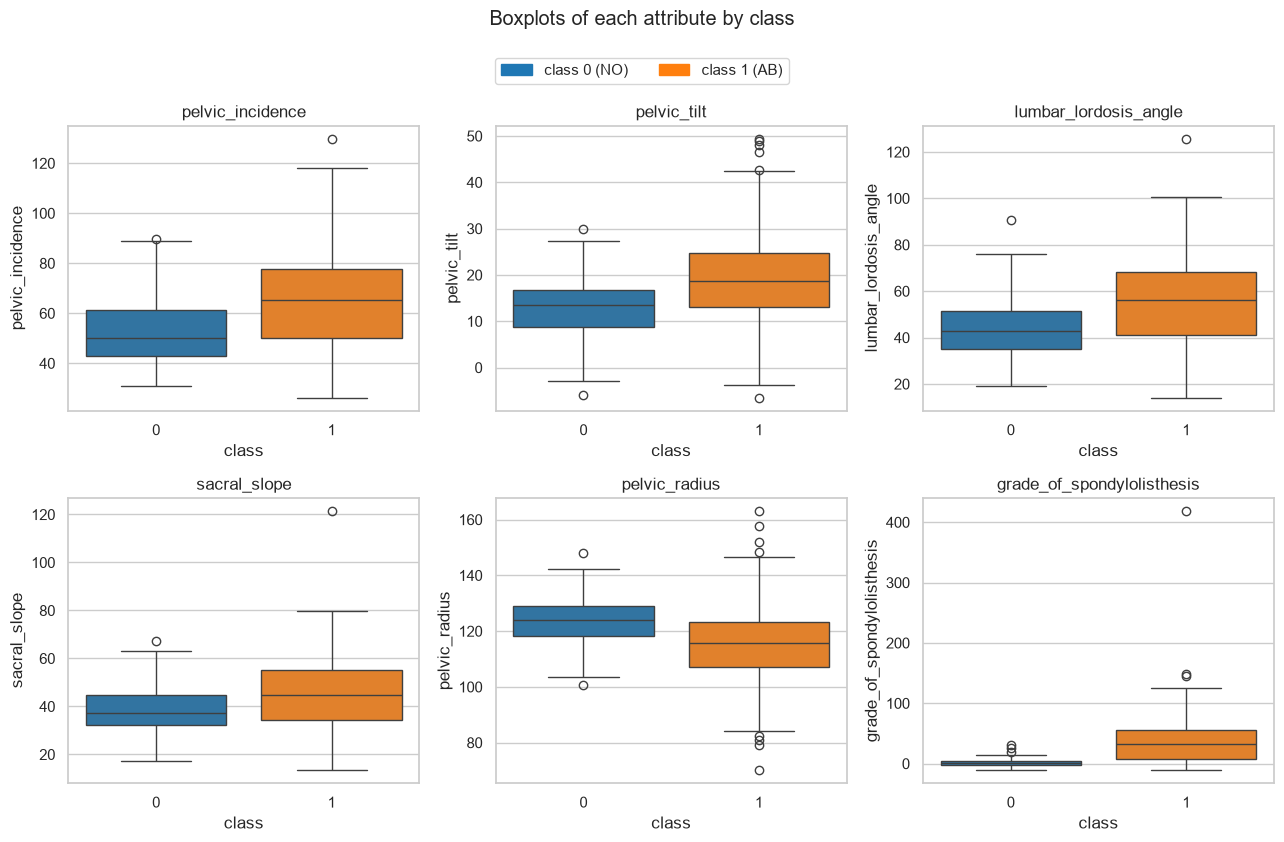

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, c in zip(axes.ravel(), cols):
    sns.boxplot(data=df, x="class", y=c, hue="class",
                palette={0: "tab:blue", 1: "tab:orange"}, legend=False, ax=ax)
    ax.set_title(c)
    ax.set_xlabel("class")
    ax.set_ylabel(c)
handles = [Patch(color="tab:blue", label="class 0 (NO)"),
           Patch(color="tab:orange", label="class 1 (AB)")]
fig.legend(handles=handles, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 1.0))
fig.suptitle("Boxplots of each attribute by class", y=1.05)
fig.tight_layout()
plt.show()

Each attribute has its own y axis, so the very different scales of the attributes do not hide any of them. Class 1 tends to have larger medians and a wider spread, and grade of spondylolisthesis again shows the largest gap between the two classes.

#### iii. Split Data Set

In [5]:
c0 = df[df["class"] == 0]
c1 = df[df["class"] == 1]

# positional split in file order: first 70 of class 0 and first 140 of class 1 train
train = pd.concat([c0.iloc[:70], c1.iloc[:140]]).sort_index()
test = pd.concat([c0.iloc[70:], c1.iloc[140:]]).sort_index()

X_train = train[cols].to_numpy()
y_train = train["class"].to_numpy()
X_test = test[cols].to_numpy()
y_test = test["class"].to_numpy()

print("train shape:", train.shape, " class counts:", np.bincount(y_train))
print("test shape: ", test.shape, " class counts:", np.bincount(y_test))

train shape: (210, 7)  class counts: [ 70 140]
test shape:  (100, 7)  class counts: [30 70]


The training set is the first 70 rows of class 0 and the first 140 rows of class 1 in file order, 210 rows in total, and the test set is the remaining 30 rows of class 0 and 70 rows of class 1, 100 rows in total. Every later part of this homework uses exactly this split.

### (c) Classification

#### i. Euclidean Metric

In [6]:
def knn_errors(k, Xtr, ytr, Xte, yte):
    # majority voting with unscaled features and the Euclidean metric
    clf = KNeighborsClassifier(n_neighbors=k, metric="euclidean", weights="uniform")
    clf.fit(Xtr, ytr)
    train_err = np.mean(clf.predict(Xtr) != ytr)
    test_err = np.mean(clf.predict(Xte) != yte)
    return train_err, test_err, clf

The classifier is KNeighborsClassifier from scikit-learn with the Euclidean metric and uniform weights, which is plain majority voting among the k nearest training points. The features are used on their original scales because this part does not ask for any rescaling, and error means the misclassification rate.

#### ii. Test Data

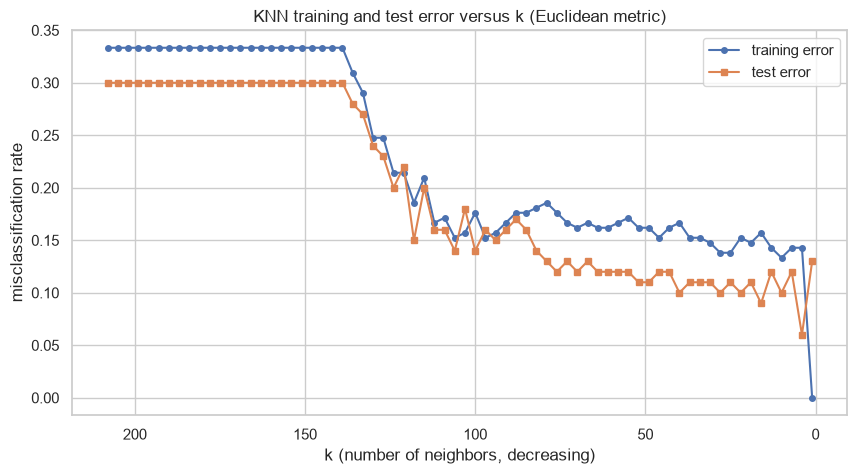

  k  train_error  test_error
208     0.333333        0.30
205     0.333333        0.30
202     0.333333        0.30
199     0.333333        0.30
196     0.333333        0.30
193     0.333333        0.30
190     0.333333        0.30
187     0.333333        0.30
184     0.333333        0.30
181     0.333333        0.30
178     0.333333        0.30
175     0.333333        0.30
172     0.333333        0.30
169     0.333333        0.30
166     0.333333        0.30
163     0.333333        0.30
160     0.333333        0.30
157     0.333333        0.30
154     0.333333        0.30
151     0.333333        0.30
148     0.333333        0.30
145     0.333333        0.30
142     0.333333        0.30
139     0.333333        0.30
136     0.309524        0.28
133     0.290476        0.27
130     0.247619        0.24
127     0.247619        0.23
124     0.214286        0.20
121     0.214286        0.22
118     0.185714        0.15
115     0.209524        0.20
112     0.166667        0.16
109     0.1714

In [7]:
ks = np.arange(208, 0, -3)
train_errs, test_errs = [], []
for k in ks:
    tr, te, _ = knn_errors(k, X_train, y_train, X_test, y_test)
    train_errs.append(tr)
    test_errs.append(te)

errors = pd.DataFrame({"k": ks, "train_error": train_errs, "test_error": test_errs})

plt.figure(figsize=(10, 5))
plt.plot(ks, train_errs, marker="o", markersize=4, label="training error")
plt.plot(ks, test_errs, marker="s", markersize=4, label="test error")
plt.gca().invert_xaxis()
plt.xlabel("k (number of neighbors, decreasing)")
plt.ylabel("misclassification rate")
plt.title("KNN training and test error versus k (Euclidean metric)")
plt.legend()
plt.show()

print(errors.to_string(index=False))

In [8]:
min_err = errors["test_error"].min()
tied = sorted(errors.loc[errors["test_error"] == min_err, "k"].tolist())
k_star = tied[0]
print("lowest test error:", round(min_err, 4))
print("k values reaching it:", tied)
print("k* =", k_star)

_, _, clf = knn_errors(k_star, X_train, y_train, X_test, y_test)
y_pred = clf.predict(X_test)

# class 1 (AB) is the positive class
tp = int(np.sum((y_pred == 1) & (y_test == 1)))
tn = int(np.sum((y_pred == 0) & (y_test == 0)))
fp = int(np.sum((y_pred == 1) & (y_test == 0)))
fn = int(np.sum((y_pred == 0) & (y_test == 1)))

cm = pd.DataFrame([[tn, fp], [fn, tp]],
                  index=["actual 0 (NO)", "actual 1 (AB)"],
                  columns=["predicted 0 (NO)", "predicted 1 (AB)"])
print(cm)
print()
tpr = tp / (tp + fn)
tnr = tn / (tn + fp)
precision = tp / (tp + fp)
f1 = 2 * precision * tpr / (precision + tpr)
print(f"true positive rate = TP / (TP + FN) = {tp} / ({tp} + {fn}) = {tpr:.4f}")
print(f"true negative rate = TN / (TN + FP) = {tn} / ({tn} + {fp}) = {tnr:.4f}")
print(f"precision          = TP / (TP + FP) = {tp} / ({tp} + {fp}) = {precision:.4f}")
print(f"F1 score           = 2 * precision * TPR / (precision + TPR) "
      f"= 2 * {precision:.4f} * {tpr:.4f} / ({precision:.4f} + {tpr:.4f}) = {f1:.4f}")

lowest test error: 0.06
k values reaching it: [4]
k* = 4
               predicted 0 (NO)  predicted 1 (AB)
actual 0 (NO)                25                 5
actual 1 (AB)                 1                69

true positive rate = TP / (TP + FN) = 69 / (69 + 1) = 0.9857
true negative rate = TN / (TN + FP) = 25 / (25 + 5) = 0.8333
precision          = TP / (TP + FP) = 69 / (69 + 5) = 0.9324
F1 score           = 2 * precision * TPR / (precision + TPR) = 2 * 0.9324 * 0.9857 / (0.9324 + 0.9857) = 0.9583


The most suitable k is taken to be the one with the lowest test error, and if several k tie at that minimum the smallest of them is used. The minimum test error of 0.06 is reached only at k = 4, so k* = 4 with no ties. The confusion matrix and the metrics above treat class 1 (AB) as the positive class, giving TPR = 0.9857, TNR = 0.8333, precision = 0.9324 and F1 = 0.9583.

#### iii. Learning Curve

k grid for N = 200: [1, 6, 11, 16, 21, 26, 31, 36, 41, 46, 51, 56, 61, 66, 71, 76, 81, 86, 91, 96, 101, 106, 111, 116, 121, 126, 131, 136, 141, 146, 151, 156, 161, 166, 171, 176, 181, 186, 191, 196]


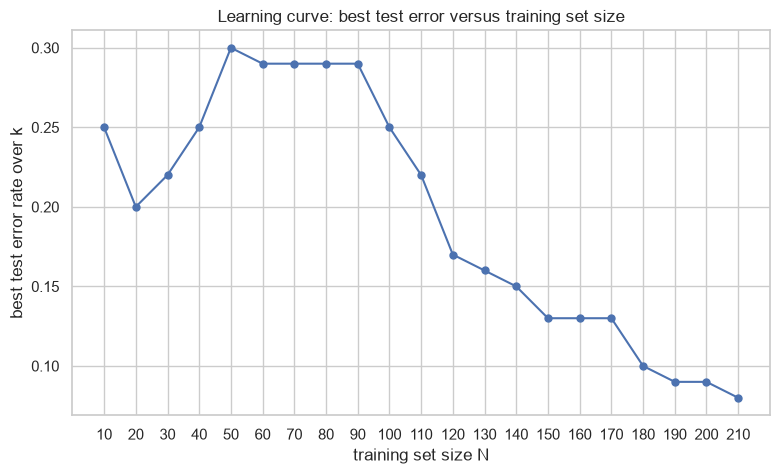

  N  best_test_error  best_k
 10             0.25       1
 20             0.20       6
 30             0.22       1
 40             0.25      11
 50             0.30      26
 60             0.29      21
 70             0.29      26
 80             0.29      31
 90             0.29      41
100             0.25       6
110             0.22       6
120             0.17      16
130             0.16      16
140             0.15      16
150             0.13      16
160             0.13       6
170             0.13       6
180             0.10       6
190             0.09       6
200             0.09       6
210             0.08       6


In [9]:
def k_grid(N):
    return np.arange(1, N + 1, 5)

print("k grid for N = 200:", k_grid(200).tolist())

t0 = train[train["class"] == 0]
t1 = train[train["class"] == 1]

Ns = np.arange(10, 211, 10)
best_errs, best_ks = [], []
for N in Ns:
    n0 = N // 3
    sub = pd.concat([t0.iloc[:n0], t1.iloc[:N - n0]]).sort_index()
    Xs = sub[cols].to_numpy()
    ys = sub["class"].to_numpy()
    results = []
    for k in k_grid(N):
        _, te, _ = knn_errors(k, Xs, ys, X_test, y_test)
        results.append((te, k))
    te_best, k_best = min(results)
    best_errs.append(te_best)
    best_ks.append(k_best)

curve = pd.DataFrame({"N": Ns, "best_test_error": best_errs, "best_k": best_ks})

plt.figure(figsize=(9, 5))
plt.plot(Ns, best_errs, marker="o", markersize=5)
plt.xlabel("training set size N")
plt.ylabel("best test error rate over k")
plt.title("Learning curve: best test error versus training set size")
plt.xticks(Ns)
plt.show()

print(curve.to_string(index=False))

For each N the candidate k values are 1, 6, 11, and so on up to the largest value not exceeding N, and the best test error over those k is plotted, with the smallest k taken when several tie. The curve is noisy and even rises for N between 40 and 90, where the training subset is small and heavily skewed towards class 1, but from about N = 100 onward the best test error falls steadily and reaches its lowest value of 0.08 at N = 210. More training data therefore helps the classifier, although the gains flatten out at the largest sizes.

### (d) Other Metrics

#### i. Minkowski Distance.

##### A. Manhattan Distance with p = 1.

In [10]:
ks_d = k_grid(196)
print("k set:", len(ks_d), "values, from", ks_d.min(), "to", ks_d.max())


def knn_sweep(ks, Xtr, ytr, Xte, yte, **kwargs):
    rows = []
    for k in ks:
        clf = KNeighborsClassifier(n_neighbors=k, **kwargs).fit(Xtr, ytr)
        rows.append((k, np.mean(clf.predict(Xtr) != ytr), np.mean(clf.predict(Xte) != yte)))
    return pd.DataFrame(rows, columns=["k", "train_error", "test_error"])


def best_k(sweep):
    # lowest test error, smallest k if several tie
    low = sweep["test_error"].min()
    tied = sweep.loc[sweep["test_error"] == low, "k"].tolist()
    train = sweep.loc[sweep["k"] == tied[0], "train_error"].item()
    return tied[0], tied, train, low


def report(name, sweep):
    k, tied, train, test = best_k(sweep)
    print(f"{name}: best k = {k}, tied k = {tied}, train error = {train:.4f}, test error = {test:.4f}")
    return k, tied, train, test


sweep_manhattan = knn_sweep(ks_d, X_train, y_train, X_test, y_test, metric="manhattan")
print(sweep_manhattan.to_string(index=False))
k_manhattan, tied_manhattan, train_manhattan, test_manhattan = report("Manhattan", sweep_manhattan)

k set: 40 values, from 1 to 196


  k  train_error  test_error
  1     0.000000        0.12
  6     0.138095        0.11
 11     0.142857        0.11
 16     0.133333        0.12
 21     0.147619        0.12
 26     0.166667        0.11
 31     0.166667        0.12
 36     0.161905        0.13
 41     0.166667        0.13
 46     0.171429        0.13
 51     0.171429        0.14
 56     0.185714        0.13
 61     0.176190        0.15
 66     0.180952        0.15
 71     0.176190        0.14
 76     0.180952        0.14
 81     0.166667        0.16
 86     0.152381        0.15
 91     0.180952        0.20
 96     0.176190        0.20
101     0.200000        0.22
106     0.204762        0.21
111     0.219048        0.23
116     0.228571        0.21
121     0.242857        0.22
126     0.261905        0.24
131     0.304762        0.28
136     0.323810        0.28
141     0.333333        0.30
146     0.333333        0.30
151     0.333333        0.30
156     0.333333        0.30
161     0.333333        0.30
166     0.3333

For parts (d) and (e) the candidate set is k in {1, 6, 11, ..., 196}, 40 values, and the best k for a metric is the one with the lowest test error, taking the smallest k when several tie. With the Manhattan distance (Minkowski with p = 1) the lowest test error is 0.11, reached at k = 6, 11 and 26, so k*_manhattan = 6 with a training error of 0.1381 at that k.

##### B. With log10(p) in {0.1, 0.2, 0.3, ... ,1}.

In [11]:
log10_ps = np.round(np.arange(0.1, 1.01, 0.1), 1)
rows = []
for lp in log10_ps:
    p = 10 ** lp
    clf = KNeighborsClassifier(n_neighbors=k_manhattan, metric="minkowski", p=p).fit(X_train, y_train)
    rows.append((lp, p, np.mean(clf.predict(X_train) != y_train), np.mean(clf.predict(X_test) != y_test)))
sweep_p = pd.DataFrame(rows, columns=["log10_p", "p", "train_error", "test_error"])

print("k held fixed at k*_manhattan =", k_manhattan)
print(sweep_p.to_string(index=False))
low_p = sweep_p["test_error"].min()
best_log10_p = sweep_p.loc[sweep_p["test_error"] == low_p, "log10_p"].tolist()
print("best log10(p):", best_log10_p, "with test error", low_p)

k held fixed at k*_manhattan = 6
 log10_p         p  train_error  test_error
     0.1  1.258925     0.138095        0.09
     0.2  1.584893     0.147619        0.09
     0.3  1.995262     0.152381        0.08
     0.4  2.511886     0.152381        0.08
     0.5  3.162278     0.147619        0.08
     0.6  3.981072     0.152381        0.06
     0.7  5.011872     0.152381        0.07
     0.8  6.309573     0.147619        0.08
     0.9  7.943282     0.147619        0.09
     1.0 10.000000     0.133333        0.09
best log10(p): [0.6] with test error 0.06


Here k is not re-selected: every p uses k = k*_manhattan = 6 from part (d)i-A, and p = 10 to the power log10(p) runs from about 1.26 to 10. The best value is log10(p) = 0.6, that is p of about 3.98, with a test error of 0.06. Most of these p are fractional, so the distance involves fractional powers and the computation is slower than for integer p; with 210 training rows this is still quick.

##### C. Chebyshev Distance With p -> infinity.

In [12]:
sweep_chebyshev = knn_sweep(ks_d, X_train, y_train, X_test, y_test, metric="chebyshev")
print(sweep_chebyshev.to_string(index=False))
k_chebyshev, tied_chebyshev, train_chebyshev, test_chebyshev = report("Chebyshev", sweep_chebyshev)

  k  train_error  test_error
  1     0.000000        0.13
  6     0.152381        0.10
 11     0.152381        0.12
 16     0.147619        0.08
 21     0.133333        0.11
 26     0.157143        0.12
 31     0.142857        0.12
 36     0.152381        0.10
 41     0.142857        0.13
 46     0.161905        0.12
 51     0.166667        0.12
 56     0.166667        0.12
 61     0.171429        0.14
 66     0.161905        0.13
 71     0.180952        0.14
 76     0.176190        0.11
 81     0.171429        0.14
 86     0.171429        0.12
 91     0.157143        0.15
 96     0.161905        0.14
101     0.171429        0.19
106     0.171429        0.18
111     0.180952        0.18
116     0.176190        0.18
121     0.209524        0.21
126     0.223810        0.21
131     0.247619        0.25
136     0.319048        0.28
141     0.333333        0.30
146     0.333333        0.30
151     0.333333        0.30
156     0.333333        0.30
161     0.333333        0.30
166     0.3333

The Chebyshev distance is the limit of the Minkowski distance as p goes to infinity, the largest absolute coordinate difference, and is used through its own metric name rather than a large finite p. Its lowest test error is 0.08 at k = 16 alone, with a training error of 0.1476 at that k.

#### ii. Mahalanobis Distance.

In [13]:
S = np.cov(X_train, rowvar=False)
eig = np.linalg.eigvalsh(S)
cond = np.linalg.cond(S)
rank = np.linalg.matrix_rank(S)
print("covariance estimated from the 210 training rows, shape", S.shape)
print("eigenvalues:", np.array2string(eig, precision=6))
print(f"condition number: {cond:.6g}   rank: {rank} of {S.shape[1]}")
threshold = 1 / np.sqrt(np.finfo(float).eps)
ill_conditioned = cond > threshold
print(f"ill-conditioned (condition number above 1/sqrt(machine eps) = {threshold:.3g}): {ill_conditioned}")

resid = X_train[:, 0] - X_train[:, 1] - X_train[:, 3]
print(f"pelvic_incidence - pelvic_tilt - sacral_slope on the training rows: max abs {np.abs(resid).max():.4f}, std {resid.std():.4f}")

if ill_conditioned:
    # the smallest eigenvalue is rounding noise from the identity above, so that direction is dropped
    VI = np.linalg.pinv(S, rcond=1e-6)
    kept = np.sum(np.linalg.svd(S, compute_uv=False) > 1e-6 * np.linalg.svd(S, compute_uv=False).max())
    print("using the pseudoinverse with rcond = 1e-6, singular values kept:", kept, "of", S.shape[1])
else:
    VI = np.linalg.inv(S)
    print("using the plain inverse")

sweep_mahalanobis = knn_sweep(ks_d, X_train, y_train, X_test, y_test,
                              metric="mahalanobis", metric_params={"VI": VI})
print(sweep_mahalanobis.to_string(index=False))
k_mahalanobis, tied_mahalanobis, train_mahalanobis, test_mahalanobis = report("Mahalanobis", sweep_mahalanobis)

covariance estimated from the 210 training rows, shape (6, 6)
eigenvalues: [9.397248e-06 6.492675e+01 9.778194e+01 1.469580e+02 3.393675e+02
 1.890654e+03]
condition number: 2.01192e+08   rank: 6 of 6
ill-conditioned (condition number above 1/sqrt(machine eps) = 6.71e+07): True
pelvic_incidence - pelvic_tilt - sacral_slope on the training rows: max abs 0.0100, std 0.0053
using the pseudoinverse with rcond = 1e-6, singular values kept: 5 of 6


  k  train_error  test_error
  1     0.000000        0.15
  6     0.138095        0.16
 11     0.157143        0.18
 16     0.152381        0.17
 21     0.161905        0.20
 26     0.161905        0.17
 31     0.171429        0.21
 36     0.171429        0.21
 41     0.180952        0.19
 46     0.185714        0.22
 51     0.166667        0.21
 56     0.166667        0.21
 61     0.176190        0.23
 66     0.180952        0.21
 71     0.171429        0.22
 76     0.171429        0.21
 81     0.185714        0.24
 86     0.195238        0.21
 91     0.190476        0.24
 96     0.195238        0.24
101     0.204762        0.24
106     0.233333        0.23
111     0.252381        0.25
116     0.271429        0.26
121     0.309524        0.29
126     0.333333        0.29
131     0.333333        0.30
136     0.333333        0.30
141     0.333333        0.30
146     0.333333        0.30
151     0.333333        0.30
156     0.333333        0.30
161     0.333333        0.30
166     0.3333

The covariance matrix is estimated from the training features only. It has full rank 6 but a condition number of about 2 times 10 to the 8, far above the 1/sqrt(machine eps) level of about 6.7 times 10 to the 7, because pelvic incidence equals pelvic tilt plus sacral slope up to the two-decimal rounding of the data (residual at most 0.01), so the smallest eigenvalue is only rounding noise and a plain inverse would weight that noise direction by about 10 to the 5. Following the footnote, the pseudoinverse with rcond = 1e-6 is used, which keeps 5 of the 6 singular values and works in the 5-dimensional subspace; with it the lowest test error is 0.15 at k = 1, with a training error of 0.

  k  train_error  test_error
  1     0.000000        0.13
  6     0.147619        0.08
 11     0.147619        0.12
 16     0.157143        0.09
 21     0.138095        0.10
 26     0.142857        0.11
 31     0.147619        0.11
 36     0.161905        0.11
 41     0.161905        0.11
 46     0.152381        0.12
 51     0.157143        0.11
 56     0.171429        0.12
 61     0.161905        0.12
 66     0.166667        0.13
 71     0.166667        0.13
 76     0.176190        0.12
 81     0.166667        0.13
 86     0.161905        0.16
 91     0.166667        0.16
 96     0.161905        0.15
101     0.185714        0.17
106     0.152381        0.14
111     0.180952        0.17
116     0.190476        0.18
121     0.214286        0.22
126     0.223810        0.21
131     0.266667        0.26
136     0.309524        0.28
141     0.333333        0.30
146     0.333333        0.30
151     0.333333        0.30
156     0.333333        0.30
161     0.333333        0.30
166     0.3333

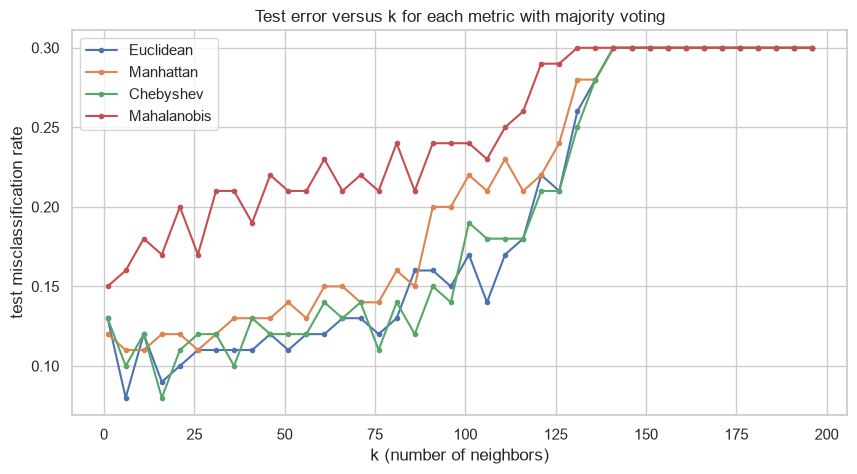

In [14]:
sweep_euclidean_d = knn_sweep(ks_d, X_train, y_train, X_test, y_test, metric="euclidean")
print(sweep_euclidean_d.to_string(index=False))
k_euclidean_d, tied_euclidean_d, train_euclidean_d, test_euclidean_d = report("Euclidean", sweep_euclidean_d)

table_d = pd.DataFrame({
    "metric": ["Euclidean", "Manhattan (p = 1)", f"Minkowski, log10(p) = {best_log10_p[0]}", "Chebyshev", "Mahalanobis"],
    "best k": [k_euclidean_d, k_manhattan, k_manhattan, k_chebyshev, k_mahalanobis],
    "test error": [test_euclidean_d, test_manhattan, low_p, test_chebyshev, test_mahalanobis],
    "train error": [train_euclidean_d, train_manhattan,
                    sweep_p.loc[sweep_p["log10_p"] == best_log10_p[0], "train_error"].item(),
                    train_chebyshev, train_mahalanobis],
})
print(table_d.to_string(index=False))

plt.figure(figsize=(10, 5))
for name, s in [("Euclidean", sweep_euclidean_d), ("Manhattan", sweep_manhattan),
                ("Chebyshev", sweep_chebyshev), ("Mahalanobis", sweep_mahalanobis)]:
    plt.plot(s["k"], s["test_error"], marker="o", markersize=3, label=name)
plt.xlabel("k (number of neighbors)")
plt.ylabel("test misclassification rate")
plt.title("Test error versus k for each metric with majority voting")
plt.legend()
plt.show()

The table gives, for each metric of part (d), the best k on the set {1, 6, ..., 196} and the test error at that k, with the Euclidean metric recomputed on the same k set as the baseline. That k set differs from the {1, 4, 7, ..., 208} used in part (c)ii, so the Euclidean row here (k = 6, test error 0.08) need not equal the 0.06 found there at k = 4. The Minkowski row uses the fixed k = 6 from (d)i-A rather than a k selected for it.

### (e) Weighted Decision

Euclidean distance, weighted voting
  k  train_error  test_error
  1          0.0        0.13
  6          0.0        0.10
 11          0.0        0.12
 16          0.0        0.11
 21          0.0        0.11
 26          0.0        0.11
 31          0.0        0.11
 36          0.0        0.11
 41          0.0        0.11
 46          0.0        0.11
 51          0.0        0.11
 56          0.0        0.11
 61          0.0        0.11
 66          0.0        0.11
 71          0.0        0.11
 76          0.0        0.12
 81          0.0        0.13
 86          0.0        0.13
 91          0.0        0.14
 96          0.0        0.14
101          0.0        0.12
106          0.0        0.14
111          0.0        0.14
116          0.0        0.13
121          0.0        0.13
126          0.0        0.13
131          0.0        0.14
136          0.0        0.14
141          0.0        0.17
146          0.0        0.19
151          0.0        0.19
156          0.0        0.20
161    

Manhattan distance, weighted voting
  k  train_error  test_error
  1          0.0        0.12
  6          0.0        0.11
 11          0.0        0.11
 16          0.0        0.12
 21          0.0        0.11
 26          0.0        0.10
 31          0.0        0.11
 36          0.0        0.11
 41          0.0        0.11
 46          0.0        0.11
 51          0.0        0.12
 56          0.0        0.12
 61          0.0        0.13
 66          0.0        0.13
 71          0.0        0.11
 76          0.0        0.12
 81          0.0        0.14
 86          0.0        0.14
 91          0.0        0.13
 96          0.0        0.13
101          0.0        0.15
106          0.0        0.15
111          0.0        0.15
116          0.0        0.15
121          0.0        0.15
126          0.0        0.15
131          0.0        0.15
136          0.0        0.16
141          0.0        0.17
146          0.0        0.18
151          0.0        0.19
156          0.0        0.21
161    

Chebyshev distance, weighted voting
  k  train_error  test_error
  1          0.0        0.13
  6          0.0        0.13
 11          0.0        0.12
 16          0.0        0.11
 21          0.0        0.12
 26          0.0        0.12
 31          0.0        0.11
 36          0.0        0.11
 41          0.0        0.11
 46          0.0        0.12
 51          0.0        0.12
 56          0.0        0.12
 61          0.0        0.11
 66          0.0        0.13
 71          0.0        0.12
 76          0.0        0.12
 81          0.0        0.12
 86          0.0        0.14
 91          0.0        0.13
 96          0.0        0.14
101          0.0        0.14
106          0.0        0.14
111          0.0        0.14
116          0.0        0.14
121          0.0        0.15
126          0.0        0.14
131          0.0        0.16
136          0.0        0.16
141          0.0        0.18
146          0.0        0.19
151          0.0        0.21
156          0.0        0.21
161    

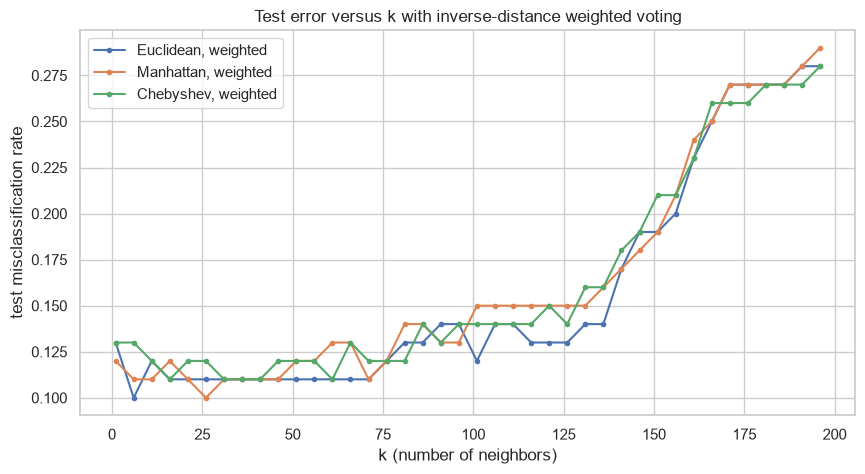

In [15]:
weighted = {}
for name, metric in [("Euclidean", "euclidean"), ("Manhattan", "manhattan"), ("Chebyshev", "chebyshev")]:
    weighted[name] = knn_sweep(ks_d, X_train, y_train, X_test, y_test, metric=metric, weights="distance")
    print(name, "distance, weighted voting")
    print(weighted[name].to_string(index=False))
    print()

unweighted = {"Euclidean": sweep_euclidean_d, "Manhattan": sweep_manhattan, "Chebyshev": sweep_chebyshev}
rows_e = []
for name, s in weighted.items():
    k, tied, train, test = report(name + " weighted", s)
    u = unweighted[name].loc[unweighted[name]["k"] == k]
    rows_e.append((name, k, tied, test, train, u["test_error"].item(), u["train_error"].item()))
table_e = pd.DataFrame(rows_e, columns=["metric", "best k", "tied k", "test error", "train error",
                                        "majority test error at same k", "majority train error at same k"])
print()
print(table_e.to_string(index=False))

plt.figure(figsize=(10, 5))
for name, s in weighted.items():
    plt.plot(s["k"], s["test_error"], marker="o", markersize=3, label=name + ", weighted")
plt.xlabel("k (number of neighbors)")
plt.ylabel("test misclassification rate")
plt.title("Test error versus k with inverse-distance weighted voting")
plt.legend()
plt.show()

With inverse-distance weighting the best test errors are 0.10 for Euclidean (k = 6), 0.10 for Manhattan (k = 26) and 0.11 for Chebyshev (k = 16, tied with 31, 36, 41 and 61), so weighting does not beat the majority-vote results of 0.08 for Euclidean and Chebyshev and 0.11 for Manhattan in part (d), nor the 0.06 of part (c)ii, although it makes the error much flatter as k grows because distant neighbours count for little. The training errors are all 0 because each training point is its own nearest neighbour at distance zero. A neighbour at distance zero would give an infinite weight; KNeighborsClassifier with weights="distance" handles this by giving weight 1 to every neighbour at zero distance and weight 0 to all others for that query, and since the training rows contain no duplicates this only happens when a training point is queried against itself.

### (f) Training Error Rate

In [16]:
records = [
    errors.assign(part="(c)ii", metric="Euclidean, majority"),
    sweep_euclidean_d.assign(part="(d)", metric="Euclidean, majority"),
    sweep_manhattan.assign(part="(d)i-A", metric="Manhattan, majority"),
    sweep_p.assign(part="(d)i-B", k=k_manhattan,
                   metric="Minkowski log10(p) = " + sweep_p["log10_p"].astype(str) + ", majority"),
    sweep_chebyshev.assign(part="(d)i-C", metric="Chebyshev, majority"),
    sweep_mahalanobis.assign(part="(d)ii", metric="Mahalanobis, majority"),
]
for name, s in weighted.items():
    records.append(s.assign(part="(e)", metric=name + ", weighted"))
all_runs = pd.concat(records)[["part", "metric", "k", "train_error", "test_error"]]

low_train = all_runs["train_error"].min()
print("lowest training error rate recorded in this homework:", low_train)
print("attained by (part, metric: k values):")
hits = all_runs[all_runs["train_error"] == low_train]
for (part, metric), ks in hits.groupby(["part", "metric"], sort=False)["k"]:
    print(f"  {part:7s} {metric}: k = {ks.tolist()}")

lowest training error rate recorded in this homework: 0.0
attained by (part, metric: k values):
  (c)ii   Euclidean, majority: k = [1]
  (d)     Euclidean, majority: k = [1]
  (d)i-A  Manhattan, majority: k = [1]
  (d)i-C  Chebyshev, majority: k = [1]
  (d)ii   Mahalanobis, majority: k = [1]
  (e)     Euclidean, weighted: k = [1, 6, 11, 16, 21, 26, 31, 36, 41, 46, 51, 56, 61, 66, 71, 76, 81, 86, 91, 96, 101, 106, 111, 116, 121, 126, 131, 136, 141, 146, 151, 156, 161, 166, 171, 176, 181, 186, 191, 196]
  (e)     Manhattan, weighted: k = [1, 6, 11, 16, 21, 26, 31, 36, 41, 46, 51, 56, 61, 66, 71, 76, 81, 86, 91, 96, 101, 106, 111, 116, 121, 126, 131, 136, 141, 146, 151, 156, 161, 166, 171, 176, 181, 186, 191, 196]
  (e)     Chebyshev, weighted: k = [1, 6, 11, 16, 21, 26, 31, 36, 41, 46, 51, 56, 61, 66, 71, 76, 81, 86, 91, 96, 101, 106, 111, 116, 121, 126, 131, 136, 141, 146, 151, 156, 161, 166, 171, 176, 181, 186, 191, 196]


The lowest training error rate in this homework is 0. It is attained at k = 1 by every majority-vote metric, namely the Euclidean sweep of (c)ii, the Euclidean, Manhattan, Chebyshev and Mahalanobis sweeps of (d), and by all three weighted metrics of (e) at every k in {1, 6, ..., 196}. At k = 1 each training point is its own nearest neighbour at distance zero and simply returns its own label, and with inverse-distance weighting that zero-distance neighbour receives all the weight whatever k is, so the training set is reproduced exactly in both cases.